# WattIf : visualisations
Deux représentations originales de dix ans de consommation : une spirale annuelle et un carpet plot.
(Les graphiques contrefactuels sont dans 03_contrefactuels.)

In [1]:
# CELLULE 2 : IMPORTS ET CHARGEMENT

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors          # palettes de couleurs et barres de couleur

os.makedirs("figures", exist_ok=True)
df = pd.read_csv("data/daily.csv", index_col="date", parse_dates=True).asfreq("D")
mois = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
print(df.shape)

(3896, 15)


## 1. Spirale de consommation
Chaque année est une boucle fermée : l'angle donne le mois, la distance au centre la consommation
moyenne. Une boucle plus petite en hiver = une année qui consomme moins.

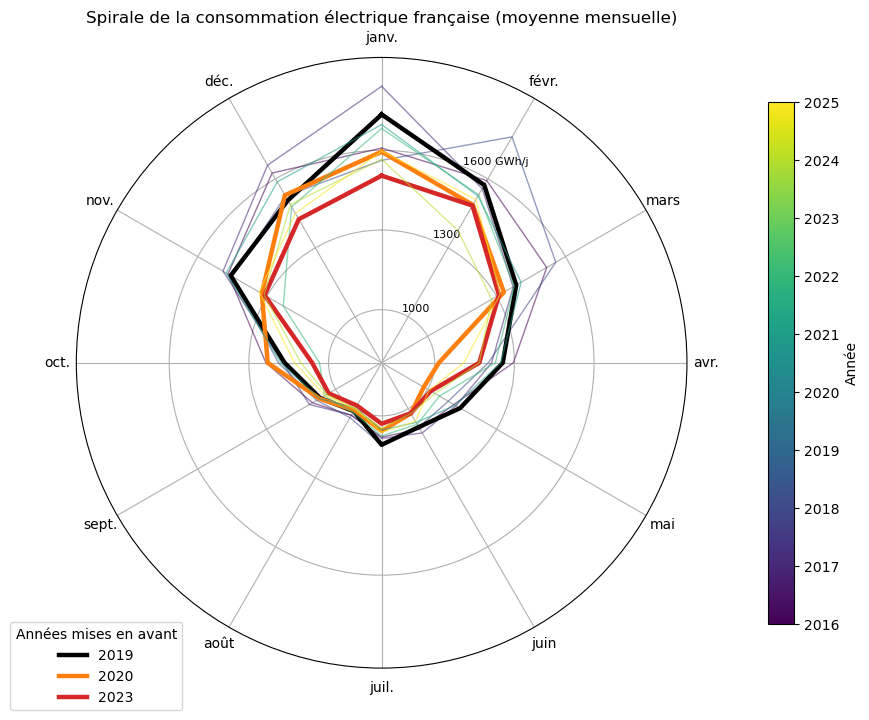

In [2]:
# CELLULE 4 : SPIRALE DE CONSOMMATION

mensuel = df["conso_gwh"].resample("MS").mean()            # moyenne mensuelle en GWh/jour
mensuel = mensuel[mensuel.index < "2026-01-01"]              # années complètes uniquement
annees = sorted(mensuel.index.year.unique())
mises_en_avant = {2019: "black", 2020: "tab:orange", 2023: "tab:red"}   # avant crise / COVID / sobriété
cmap = plt.get_cmap("viridis")
norm = colors.Normalize(vmin=annees[0], vmax=annees[-1])

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(projection="polar")
for an in annees:
    s = mensuel[mensuel.index.year == an]
    theta = 2 * np.pi * (s.index.month - 1) / 12              # mois → angle
    theta = np.append(theta, 2 * np.pi)                       # on referme la boucle
    r = np.append(s.values, s.values[0])
    if an in mises_en_avant:
        ax.plot(theta, r, color=mises_en_avant[an], lw=3.2, label=str(an))
    else:
        ax.plot(theta, r, color=cmap(norm(an)), lw=1.0, alpha=0.55)

ax.set_theta_zero_location("N")                              # janvier en haut
ax.set_theta_direction(-1)                                   # sens des aiguilles d'une montre
ax.set_xticks(2 * np.pi * np.arange(12) / 12)
ax.set_xticklabels(mois)
ax.set_ylim(800, 1950)
ax.set_yticks([1000, 1300, 1600])
ax.set_yticklabels(["1000", "1300", "1600 GWh/j"], fontsize=8)
cb = fig.colorbar(cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, shrink=0.6, pad=0.1)
cb.set_label("Année")
ax.legend(loc="lower left", bbox_to_anchor=(-0.12, -0.08), title="Années mises en avant")
ax.set_title("Spirale de la consommation électrique française (moyenne mensuelle)", pad=25)
plt.tight_layout()
plt.savefig("figures/spirale.png", dpi=150, bbox_inches="tight")
plt.show()

### Lecture
La forme de « cœur » traduit la saisonnalité annuelle : lobe d'hiver large, été resserré.
2020 (orange) se creuse en avril : c'est le confinement. 2023 (rouge) passe à l'intérieur
de toutes les autres années en hiver : c'est la sobriété. En été, toutes les boucles se
superposent : les deux chocs ont surtout touché les usages d'hiver et l'activité économique.

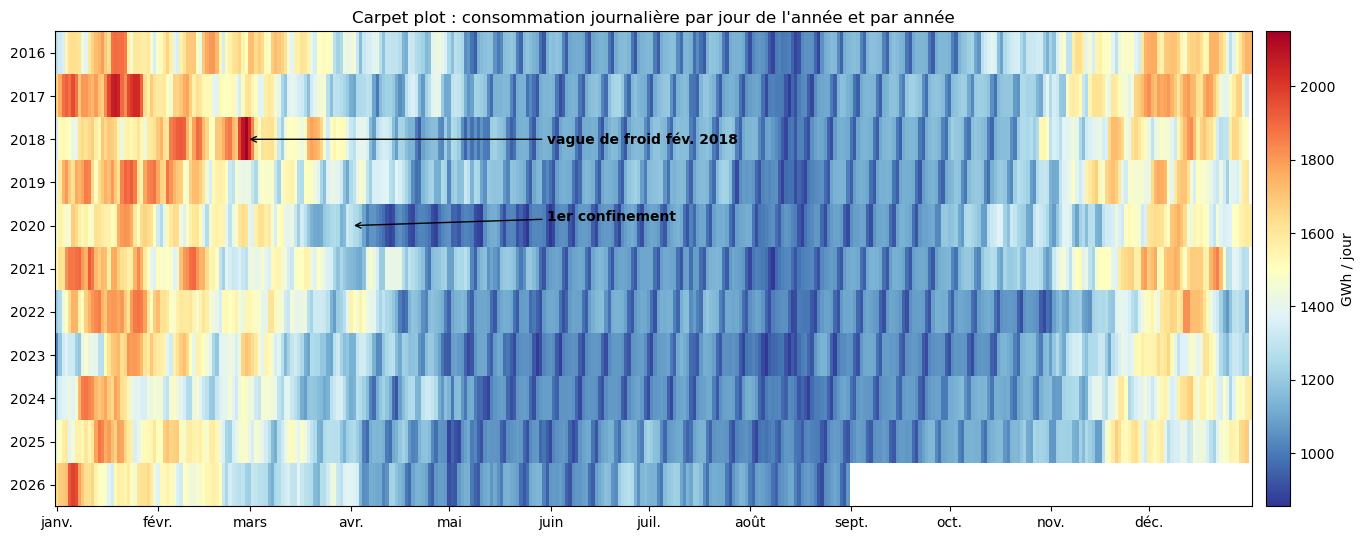

In [3]:
# CELLULE 6 : CARPET PLOT (ANNÉE × JOUR DE L'ANNÉE)

# --- Tableau : une ligne par année, une colonne par jour de l'année ---
tab = df.assign(annee=df.index.year, jour=df.index.dayofyear).pivot_table(
    index="annee", columns="jour", values="conso_gwh")

fig, ax = plt.subplots(figsize=(15, 5.5))
im = ax.imshow(tab.values, aspect="auto", cmap="RdYlBu_r", interpolation="nearest")   # rouge = forte conso
ax.set_yticks(range(len(tab.index)))
ax.set_yticklabels(tab.index)
debuts_mois = pd.date_range("2021-01-01", periods=12, freq="MS").dayofyear - 1
ax.set_xticks(debuts_mois)
ax.set_xticklabels(mois)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("GWh / jour")

# --- Annotations des événements ---
ax.annotate("vague de froid fév. 2018", xy=(58, tab.index.get_loc(2018)), xytext=(150, tab.index.get_loc(2018)),
            fontsize=10, fontweight="bold", arrowprops=dict(arrowstyle="->"), va="center")
ax.annotate("1er confinement", xy=(90, tab.index.get_loc(2020)), xytext=(150, tab.index.get_loc(2020) - 0.2),
            fontsize=10, fontweight="bold", arrowprops=dict(arrowstyle="->"), va="center")
ax.set_title("Carpet plot : consommation journalière par jour de l'année et par année")
plt.tight_layout()
plt.savefig("figures/carpet_plot.png", dpi=150, bbox_inches="tight")
plt.show()

### Lecture
Chaque pixel est un jour. Les rayures verticales régulières sont les week-ends (saisonnalité
hebdomadaire), les bandes rouges les hivers (saisonnalité annuelle). On repère à l'œil :
la vague de froid de fin février 2018 (pixels rouge foncé), le bleu anormal du printemps 2020
(confinement), le creux du mois d'août chaque année, et le « refroidissement » des couleurs
d'hiver à partir de fin 2022 (sobriété). En une seule image, on retrouve toute l'analyse.